# 02. Baseline cho chuỗi phụ MT_169 và MT_294

**Mục tiêu:** chạy bốn baseline (Last Value, Moving Average 3 giờ, Seasonal Naive 24 giờ, Seasonal Naive 168 giờ)
cho hai chuỗi phụ **MT_169 (40 kW)** và **MT_294 (641 kW)**, theo đúng quy trình đã dùng cho chuỗi chính MT_158
và chuỗi MT_168, để bảng so sánh bốn chuỗi trong Chương 3 cùng một phương pháp.

**Quy ước (giữ nguyên từ Nhiệm vụ 1 và 2):**
- Dữ liệu là kW trung bình mỗi giờ, nhãn thời gian là mốc kết thúc của giờ.
- Chia theo thời gian: 27.720 / 3.672 / 3.672 giờ. Ngữ cảnh lịch sử 168 giờ lấy từ chuỗi đầy đủ, nhưng **nhãn chỉ lấy trong tập đích**,
  nên mọi baseline đều được chấm trên đúng 3.672 mốc.
- MASE dùng mẫu số naive-1 tính trên tập train (`d_train`).
- Chọn baseline tốt nhất chỉ dựa trên **validation**; test chỉ để báo cáo.

**Cách chạy:** mở notebook trong thư mục `notebooks/` hoặc ở thư mục gốc, chạy lần lượt từ trên xuống.
Cần có `data/processed/series_hourly.csv`. Kết quả ghi vào `results/` với hậu tố tên chuỗi (ví dụ `baseline_results_MT_169.csv`).

In [1]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.baseline import BASELINE_COLUMNS, get_common_eval_timestamps, predict_baselines
from src.config import load_config, path_from, set_seed
from src.data import load_hourly_data, split_by_time
from src.dst_check import dst_timestamps
from src.metrics import calculate_d_train, evaluate_by_group, evaluate_forecast

cfg = load_config()
set_seed(cfg["project"]["seed"])

# Hai chuỗi phụ thuộc phần việc của Gia Long. Chuỗi chính và MT_168 đã chạy ở các notebook khác.
CHAINS = ["MT_169", "MT_294"]

FIG_DIR = path_from(cfg, "figures_dir"); FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = path_from(cfg, "tables_dir");  TAB_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results";              RES_DIR.mkdir(exist_ok=True)
MODEL_DIR = path_from(cfg, "models_dir"); MODEL_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Chuỗi chạy:", CHAINS, "| chuỗi chính của nhóm:", cfg["customers"]["main"])

Chuỗi chạy: ['MT_169', 'MT_294'] | chuỗi chính của nhóm: MT_158


## 1. Đọc dữ liệu và chia tập

`load_hourly_data` kiểm tra dữ liệu (không trùng, không thiếu, không âm, cách đều 1 giờ) và dừng nếu sai.
`split_by_time` kiểm tra số dòng từng tập đúng 27.720 / 3.672 / 3.672.

In [2]:
full_df = load_hourly_data(cfg, customers=CHAINS)
train_df, val_df, test_df = split_by_time(full_df, cfg)

print(f"Tổng: {len(full_df):,} giờ ({full_df.index.min()} -> {full_df.index.max()})")
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,} giờ")
full_df.describe().round(2)

Tổng: 35,064 giờ (2011-01-01 01:00:00 -> 2015-01-01 00:00:00)
Train: 27,720 | Validation: 3,672 | Test: 3,672 giờ


,MT_169,MT_294
count,35064.00,35064.00
mean,40.03,641.02
std,11.24,194.47
min,7.06,78.61
25%,28.77,453.91
50%,43.52,666.04
75%,49.58,781.98
max,71.32,1461.17


## 2. Tính `d_train` và chuẩn hóa

`d_train` là trung bình |y_t − y_(t−1)| trên **tập train** của từng chuỗi, dùng làm mẫu số của MASE.

Bộ chuẩn hóa `StandardScaler` được khớp **chỉ trên tập train**, **mỗi chuỗi một bộ riêng** và lưu thành
`models/scaler_<tên chuỗi>.pkl` để mô hình học sâu khôi phục đúng thang đo gốc. Baseline vẫn dự báo trên giá trị kW gốc,
nên scaler ở đây chỉ để bàn giao cho Hồng Sơn và Bảo Quốc.

In [3]:
d_train = {}
scaler_info = []
for c in CHAINS:
    d_train[c] = calculate_d_train(train_df[c].to_numpy(dtype=float))
    if not np.isfinite(d_train[c]) or d_train[c] <= 0:
        raise ValueError(f"d_train không hợp lệ cho {c}: {d_train[c]}")

    scaler = StandardScaler().fit(train_df[[c]].to_numpy())   # ép 1 cột, chỉ trên train
    joblib.dump(scaler, MODEL_DIR / f"scaler_{c}.pkl")
    scaler_info.append({"customer": c, "d_train": d_train[c],
                        "scaler_mean": scaler.mean_[0], "scaler_scale": scaler.scale_[0]})

pd.DataFrame(scaler_info).set_index("customer").round(4)

,d_train,scaler_mean,scaler_scale
customer,,,
MT_169,3.0747,39.6525,11.3198
MT_294,56.8083,652.3167,200.3224


## 3. Mốc thời gian đánh giá

`get_common_eval_timestamps` giữ những mốc có đủ 168 giờ lịch sử, tính trên chuỗi đầy đủ. Vì ngữ cảnh được lấy từ cuối tập liền trước,
cả validation và test đều giữ đủ 3.672 mốc. Phần kiểm tra bên dưới xác nhận danh sách mốc trùng khít index của từng tập.

In [4]:
val_ts, test_ts = {}, {}
for c in CHAINS:
    full_series = full_df[c].astype(float)
    val_ts[c] = get_common_eval_timestamps(full_series, val_df.index)
    test_ts[c] = get_common_eval_timestamps(full_series, test_df.index)

    assert val_ts[c].equals(val_df.index), f"{c}: mốc validation lệch index tập"
    assert test_ts[c].equals(test_df.index), f"{c}: mốc test lệch index tập"
    print(f"{c}: validation {len(val_ts[c]):,} mốc, test {len(test_ts[c]):,} mốc (khớp index tập)")

MT_169: validation 3,672 mốc, test 3,672 mốc (khớp index tập)
MT_294: validation 3,672 mốc, test 3,672 mốc (khớp index tập)


## 4. Dự báo và đánh giá trên validation

Dự báo cho từng mốc chỉ dùng giá trị **trước** mốc đó (Last Value: t−1; MA3: t−3 đến t−1; Seasonal Naive: t−24 hoặc t−168).
Mô hình tốt nhất được chọn theo MAE trên validation.

In [5]:
val_pred, val_res, best_model = {}, {}, {}
for c in CHAINS:
    full_series = full_df[c].astype(float)
    pred = predict_baselines(full_series, val_ts[c])
    y_true = pred["y_true"].to_numpy(dtype=float)

    metrics = {}
    for col in BASELINE_COLUMNS:
        y_pred = pred[col].to_numpy(dtype=float)
        if not (np.isfinite(y_true).all() and np.isfinite(y_pred).all()):
            raise ValueError(f"{c}: có NaN/Inf ở {col}")
        metrics[col] = evaluate_forecast(y_true, y_pred, d_train=d_train[c])

    res = pd.DataFrame(metrics).T
    res.index.name = "model"
    val_pred[c], val_res[c] = pred, res.sort_values("MAE")
    best_model[c] = val_res[c].index[0]

    print(f"\n=== {c}: KẾT QUẢ VALIDATION (n = {len(y_true):,}) ===")
    print(val_res[c].round(4).to_string())
    print(f"-> Mô hình tốt nhất theo MAE validation: {best_model[c]}")


=== MT_169: KẾT QUẢ VALIDATION (n = 3,672) ===
                 MAE    RMSE    MASE  N_samples
model                                          
y_snaive24    2.3044  3.1424  0.7495     3672.0
y_snaive168   2.7443  3.6566  0.8925     3672.0
y_last_value  3.3220  4.3669  1.0804     3672.0
y_ma3         5.0358  6.3893  1.6378     3672.0
-> Mô hình tốt nhất theo MAE validation: y_snaive24



=== MT_294: KẾT QUẢ VALIDATION (n = 3,672) ===
                  MAE     RMSE    MASE  N_samples
model                                            
y_snaive24    30.2833  44.0746  0.5331     3672.0
y_last_value  48.6184  68.3552  0.8558     3672.0
y_snaive168   50.4878  70.8177  0.8887     3672.0
y_ma3         73.3206  99.4026  1.2907     3672.0
-> Mô hình tốt nhất theo MAE validation: y_snaive24


## 5. Đánh giá trên test

Test chỉ dùng để **báo cáo** cả bốn baseline, không dùng để chọn mô hình. Mô hình được xem là "tốt nhất" vẫn là mô hình đã chọn ở validation.

In [6]:
test_pred, test_res = {}, {}
for c in CHAINS:
    full_series = full_df[c].astype(float)
    pred = predict_baselines(full_series, test_ts[c])
    y_true = pred["y_true"].to_numpy(dtype=float)

    metrics = {}
    for col in BASELINE_COLUMNS:
        y_pred = pred[col].to_numpy(dtype=float)
        if not (np.isfinite(y_true).all() and np.isfinite(y_pred).all()):
            raise ValueError(f"{c}: có NaN/Inf ở test, cột {col}")
        metrics[col] = evaluate_forecast(y_true, y_pred, d_train=d_train[c])

    res = pd.DataFrame(metrics).T
    res.index.name = "model"
    test_pred[c], test_res[c] = pred, res

    print(f"\n=== {c}: KẾT QUẢ TEST (n = {len(y_true):,}) ===")
    print(res.round(4).to_string())
    print(f"-> Mô hình chọn từ validation: {best_model[c]}, MAE test = {res.loc[best_model[c], 'MAE']:.4f}")


=== MT_169: KẾT QUẢ TEST (n = 3,672) ===
                 MAE    RMSE    MASE  N_samples
model                                          
y_last_value  3.3581  4.5873  1.0922     3672.0
y_ma3         5.2799  6.8451  1.7172     3672.0
y_snaive24    2.5374  3.7395  0.8252     3672.0
y_snaive168   2.7789  3.8516  0.9038     3672.0
-> Mô hình chọn từ validation: y_snaive24, MAE test = 2.5374



=== MT_294: KẾT QUẢ TEST (n = 3,672) ===
                  MAE      RMSE    MASE  N_samples
model                                             
y_last_value  48.7905   69.2540  0.8589     3672.0
y_ma3         74.3725  101.3714  1.3092     3672.0
y_snaive24    32.7992   55.2176  0.5774     3672.0
y_snaive168   42.7544   64.3391  0.7526     3672.0
-> Mô hình chọn từ validation: y_snaive24, MAE test = 32.7992


## 6. Kiểm tra không rò rỉ dữ liệu tương lai

Lấy ngẫu nhiên 300 mẫu của tập test cho mỗi chuỗi, tự tính lại bốn công thức từ chuỗi gốc rồi so với cột dự báo.
Seed lấy từ config nên chạy lại cho cùng kết quả.

In [7]:
rng = np.random.default_rng(cfg["project"]["seed"])
for c in CHAINS:
    s = full_df[c].astype(float)
    pred = test_pred[c]
    idx = rng.choice(len(pred), size=300, replace=False)
    bad = 0
    for i in idx:
        ts = pred.loc[i, "timestamp"]
        p = s.index.get_loc(ts)
        expected = {
            "y_true": s.iloc[p],
            "y_last_value": s.iloc[p - 1],
            "y_ma3": s.iloc[p - 3:p].mean(),
            "y_snaive24": s.iloc[p - 24],
            "y_snaive168": s.iloc[p - 168],
        }
        bad += sum(not np.isclose(pred.loc[i, k], v) for k, v in expected.items())
    print(f"{c}: 300 mẫu x 5 cột, số giá trị sai = {bad}")
    assert bad == 0

MT_169: 300 mẫu x 5 cột, số giá trị sai = 0


MT_294: 300 mẫu x 5 cột, số giá trị sai = 0


## 7. Phân tích sai số của mô hình tốt nhất

Gom sai số theo giờ trong ngày (nhãn là mốc kết thúc giờ) và theo thứ trong tuần trên tập test, rồi liệt kê 10 dự báo sai nhiều nhất.
Mỗi mốc ngày chuyển giờ (DST) được kiểm tra xem có lọt vào top-10 hay không.

In [8]:
err_hour, err_dow, top10 = {}, {}, {}
dst_set = {ts for ts, _ in dst_timestamps(cfg)}

for c in CHAINS:
    m = best_model[c]
    df = test_pred[c].copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"])

    err_hour[c] = evaluate_by_group(df, pred_col=m, group_by="hour")
    err_dow[c] = evaluate_by_group(df, pred_col=m, group_by="dayofweek")

    df["abs_error"] = (df["y_true"] - df[m]).abs()
    top10[c] = df.sort_values("abs_error", ascending=False).head(10)

    h = err_hour[c].sort_values("MAE")
    print(f"\n=== {c} - mô hình {m} ===")
    print("Giờ (nhãn) sai nhiều nhất:", h.tail(3)["hour"].tolist()[::-1],
          "| ít nhất:", h.head(3)["hour"].tolist())
    print("MAE theo thứ (0=T2 ... 6=CN):", err_dow[c].set_index("dayofweek")["MAE"].round(2).to_dict())
    print("Số mẫu theo thứ:", err_dow[c].set_index("dayofweek")["N_samples"].to_dict())
    n_dst = int(top10[c]["timestamp"].isin(dst_set).sum())
    print(f"Mốc DST trong top-10 sai số lớn nhất: {n_dst}/10")
    display(top10[c].round(2))


=== MT_169 - mô hình y_snaive24 ===
Giờ (nhãn) sai nhiều nhất: [22, 21, 23] | ít nhất: [5, 4, 3]
MAE theo thứ (0=T2 ... 6=CN): {0: 3.32, 1: 2.61, 2: 2.25, 3: 2.42, 4: 2.28, 5: 2.08, 6: 2.8}
Số mẫu theo thứ: {0: 528, 1: 528, 2: 528, 3: 505, 4: 527, 5: 528, 6: 528}
Mốc DST trong top-10 sai số lớn nhất: 1/10


C:\Users\sonna\AppData\Local\Temp\ipykernel_16012\3696468040.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(top10[c].round(2))


,timestamp,y_true,y_last_value,y_ma3,y_snaive24,y_snaive168,abs_error
2089,2014-10-27 02:00:00,26.16,27.90,29.34,53.00,28.62,26.84
3513,2014-12-25 10:00:00,28.77,29.06,28.96,52.40,49.55,23.63
3516,2014-12-25 13:00:00,28.04,28.48,28.48,51.29,45.46,23.25
3515,2014-12-25 12:00:00,28.48,28.19,28.67,50.80,46.04,22.32
3517,2014-12-25 14:00:00,28.33,28.04,28.24,50.57,45.18,22.24
2065,2014-10-26 02:00:00,53.00,43.89,39.59,31.23,29.49,21.77
3538,2014-12-26 11:00:00,49.73,49.26,46.44,28.19,49.73,21.54
3547,2014-12-26 20:00:00,49.55,47.08,48.71,28.19,49.55,21.36
3544,2014-12-26 17:00:00,51.58,49.00,44.82,31.08,51.58,20.50
3537,2014-12-26 10:00:00,49.26,47.99,43.29,28.77,49.26,20.49



=== MT_294 - mô hình y_snaive24 ===
Giờ (nhãn) sai nhiều nhất: [13, 12, 17] | ít nhất: [3, 4, 2]
MAE theo thứ (0=T2 ... 6=CN): {0: 31.0, 1: 27.04, 2: 32.03, 3: 37.18, 4: 40.93, 5: 31.01, 6: 30.61}
Số mẫu theo thứ: {0: 528, 1: 528, 2: 528, 3: 505, 4: 527, 5: 528, 6: 528}
Mốc DST trong top-10 sai số lớn nhất: 0/10


C:\Users\sonna\AppData\Local\Temp\ipykernel_16012\3696468040.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(top10[c].round(2))


,timestamp,y_true,y_last_value,y_ma3,y_snaive24,y_snaive168,abs_error
3540,2014-12-26 13:00:00,817.57,691.41,665.35,294.16,817.57,523.41
3545,2014-12-26 18:00:00,806.55,770.96,741.47,301.76,806.55,504.79
3546,2014-12-26 19:00:00,770.96,806.55,772.66,313.60,770.96,457.36
3544,2014-12-26 17:00:00,770.96,740.46,731.87,313.60,770.96,457.36
3543,2014-12-26 16:00:00,740.46,712.97,757.57,299.23,740.46,441.23
3547,2014-12-26 20:00:00,754.02,770.96,782.82,322.90,754.02,431.12
3536,2014-12-26 09:00:00,735.85,680.41,553.08,306.83,735.85,429.02
3522,2014-12-25 19:00:00,313.60,301.76,304.86,731.99,792.15,418.40
3541,2014-12-26 14:00:00,742.16,817.57,723.74,326.28,742.16,415.89
3521,2014-12-25 18:00:00,301.76,313.60,309.94,705.73,781.98,403.97


**Chú thích về số mẫu theo thứ:** số mẫu không đều giữa các thứ vì tập test bắt đầu lúc 01:00 ngày 01/08/2014 và kết thúc lúc 00:00 ngày 01/01/2015,
nên hai ngày biên bị cắt bớt giờ. Đây không phải lỗi dữ liệu.

## 8. Biểu đồ

Ba biểu đồ cho mỗi chuỗi: so sánh MAE/RMSE bốn baseline trên validation, dự báo tuần đầu của test, và MAE theo giờ trong ngày.

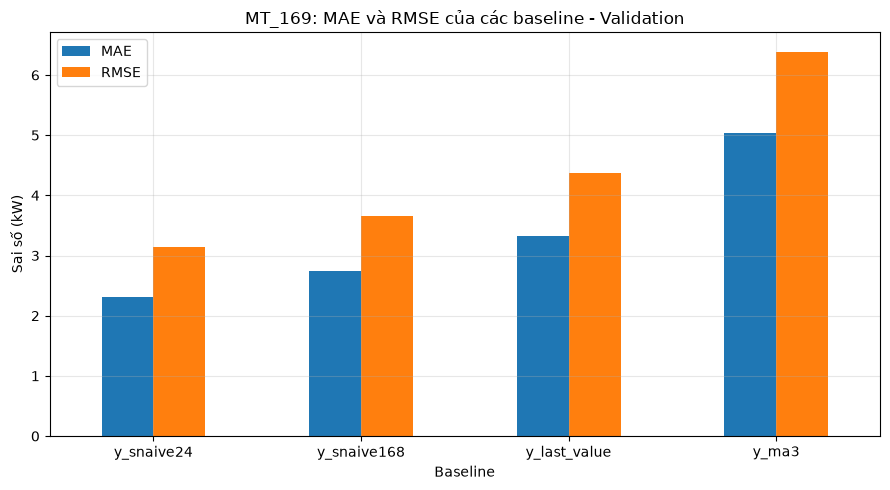

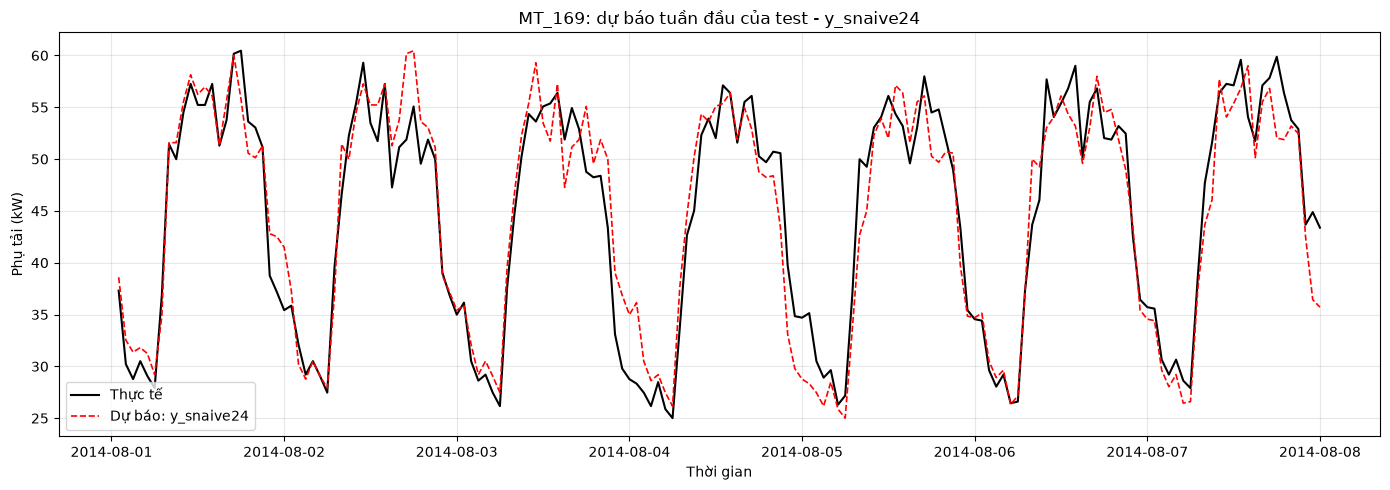

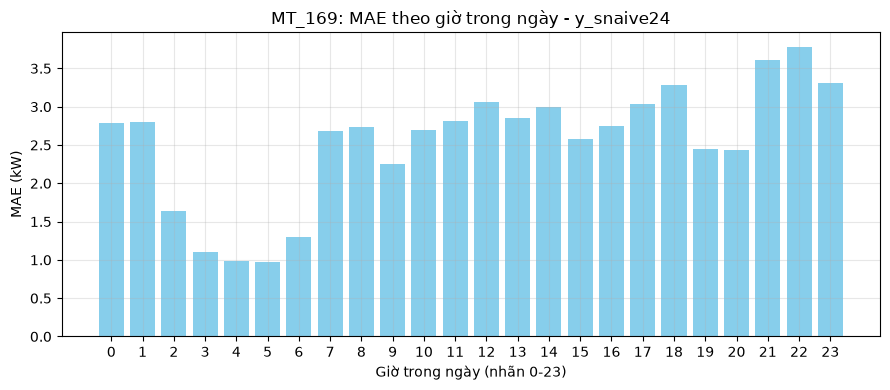

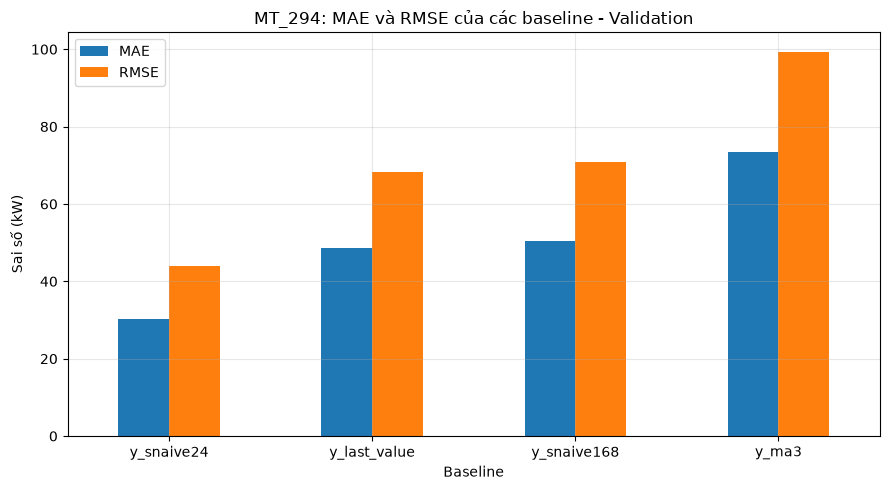

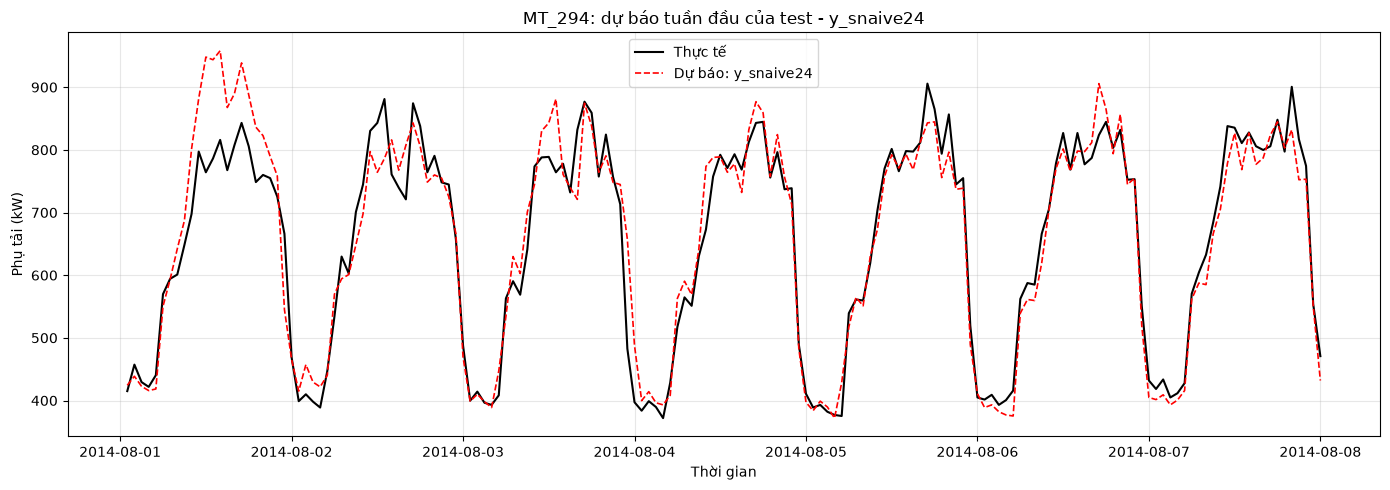

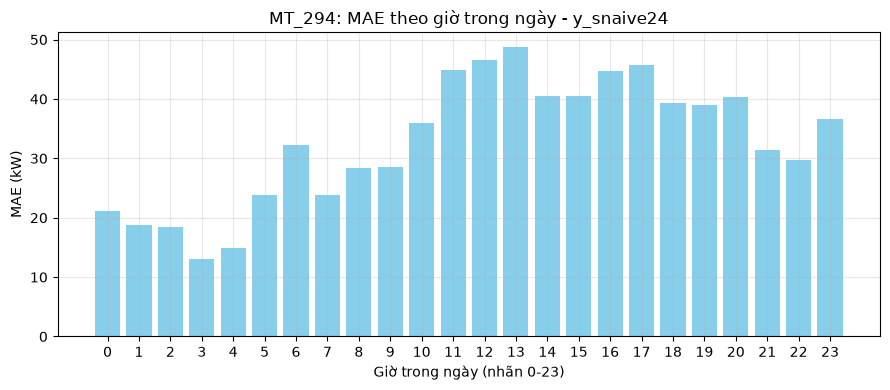

In [9]:
for c in CHAINS:
    m = best_model[c]

    ax = val_res[c][["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5))
    ax.set(title=f"{c}: MAE và RMSE của các baseline - Validation", xlabel="Baseline", ylabel="Sai số (kW)")
    plt.xticks(rotation=0); plt.tight_layout()
    plt.savefig(FIG_DIR / f"baseline_val_comparison_{c}.png", dpi=200); plt.show()

    n = min(168, len(test_pred[c]))
    ts = pd.to_datetime(test_pred[c]["timestamp"])[:n]
    plt.figure(figsize=(14, 5))
    plt.plot(ts, test_pred[c]["y_true"][:n], label="Thực tế", color="black", linewidth=1.5)
    plt.plot(ts, test_pred[c][m][:n], label=f"Dự báo: {m}", color="red", linestyle="--", linewidth=1.2)
    plt.title(f"{c}: dự báo tuần đầu của test - {m}")
    plt.xlabel("Thời gian"); plt.ylabel("Phụ tải (kW)"); plt.legend(); plt.tight_layout()
    plt.savefig(FIG_DIR / f"baseline_test_timeseries_{c}.png", dpi=200); plt.show()

    plt.figure(figsize=(9, 4))
    plt.bar(err_hour[c]["hour"], err_hour[c]["MAE"], color="skyblue")
    plt.title(f"{c}: MAE theo giờ trong ngày - {m}")
    plt.xlabel("Giờ trong ngày (nhãn 0-23)"); plt.ylabel("MAE (kW)"); plt.xticks(range(24)); plt.tight_layout()
    plt.savefig(FIG_DIR / f"baseline_error_by_hour_{c}.png", dpi=200); plt.show()

## 9. Lưu kết quả

Mọi tệp có hậu tố tên chuỗi để không ghi đè kết quả của MT_158 và MT_168.
`baseline_predictions_<chuỗi>.csv` gộp validation và test; `eval_timestamps_<chuỗi>.csv` là danh sách mốc đánh giá chung cho mô hình học sâu.

In [10]:
saved = []
for c in CHAINS:
    v = val_pred[c].copy(); v.insert(0, "split", "validation")
    t = test_pred[c].copy(); t.insert(0, "split", "test")

    files = {
        TAB_DIR / f"baseline_results_{c}.csv": (val_res[c], True),
        TAB_DIR / f"baseline_test_results_{c}.csv": (test_res[c], True),
        TAB_DIR / f"error_by_hour_{c}.csv": (err_hour[c], False),
        TAB_DIR / f"error_by_dayofweek_{c}.csv": (err_dow[c], False),
        TAB_DIR / f"top10_worst_errors_{c}.csv": (top10[c], False),
        RES_DIR / f"baseline_predictions_validation_{c}.csv": (val_pred[c], False),
        RES_DIR / f"baseline_predictions_test_{c}.csv": (test_pred[c], False),
        RES_DIR / f"baseline_predictions_{c}.csv": (pd.concat([v, t], ignore_index=True), False),
        RES_DIR / f"eval_timestamps_{c}.csv": (pd.concat(
            [pd.DataFrame({"split": "validation", "timestamp": val_ts[c]}),
             pd.DataFrame({"split": "test", "timestamp": test_ts[c]})], ignore_index=True), False),
    }
    for path, (frame, keep_index) in files.items():
        frame.to_csv(path, index=keep_index)
        saved.append(path.relative_to(ROOT).as_posix())

print(f"Đã lưu {len(saved)} tệp kết quả + {len(CHAINS)} scaler trong models/:")
print("\n".join(saved))

Đã lưu 18 tệp kết quả + 2 scaler trong models/:
results/tables/baseline_results_MT_169.csv
results/tables/baseline_test_results_MT_169.csv
results/tables/error_by_hour_MT_169.csv
results/tables/error_by_dayofweek_MT_169.csv
results/tables/top10_worst_errors_MT_169.csv
results/baseline_predictions_validation_MT_169.csv
results/baseline_predictions_test_MT_169.csv
results/baseline_predictions_MT_169.csv
results/eval_timestamps_MT_169.csv
results/tables/baseline_results_MT_294.csv
results/tables/baseline_test_results_MT_294.csv
results/tables/error_by_hour_MT_294.csv
results/tables/error_by_dayofweek_MT_294.csv
results/tables/top10_worst_errors_MT_294.csv
results/baseline_predictions_validation_MT_294.csv
results/baseline_predictions_test_MT_294.csv
results/baseline_predictions_MT_294.csv
results/eval_timestamps_MT_294.csv


## 10. Tổng hợp bốn chuỗi

Ghép kết quả MT_169 và MT_294 với MT_158 (chuỗi chính) và MT_168 do Đăng Long chạy, nếu các tệp đó có trong kho.
Bảng này là nguyên liệu cho Chương 3 và cho lập luận chọn chuỗi: chuỗi có `ac_lag24` cao thì Seasonal Naive 24 giờ thắng.

In [11]:
sources = {
    "MT_158": TAB_DIR / "baseline_results.csv",
    "MT_168": ROOT / "notebooks" / "results" / "MT_168" / "tables" / "baseline_results.csv",
    "MT_169": TAB_DIR / "baseline_results_MT_169.csv",
    "MT_294": TAB_DIR / "baseline_results_MT_294.csv",
}
rows = []
for c, p in sources.items():
    if not p.exists():
        print(f"Chưa có {p.relative_to(ROOT).as_posix()}, bỏ qua {c}")
        continue
    r = pd.read_csv(p).set_index("model")["MAE"]
    rows.append({"customer": c, **{k: r[k] for k in BASELINE_COLUMNS}, "best": r.idxmin()})

pd.DataFrame(rows).set_index("customer").round(2)

,y_last_value,y_ma3,y_snaive24,y_snaive168,best
customer,,,,,
MT_158,10.60,14.54,26.26,13.81,y_last_value
MT_168,12.12,18.96,6.92,8.44,y_snaive24
MT_169,3.32,5.04,2.30,2.74,y_snaive24
MT_294,48.62,73.32,30.28,50.49,y_snaive24


## 11. Nhận xét

1. **Seasonal Naive 24 giờ thắng áp đảo trên cả hai chuỗi, ở cả validation lẫn test.** MAE validation: MT_169 là 2,30 (Last Value 3,32), MT_294 là 30,28 (Last Value 48,62).
   Điều này đúng như `ac_lag24` đã dự đoán ở bước chọn chuỗi (0,950 và 0,944): chu kỳ ngày lặp gần như máy móc nên "giá trị cùng giờ hôm qua" đã bám sát chuỗi.
   Đây là lý do hai chuỗi này chỉ đóng vai trò kiểm tra tính tổng quát, còn MT_158 (`ac_lag24` = 0,560, Last Value dẫn đầu) mới là chuỗi còn dư địa cho mô hình học sâu.
2. **Thứ hạng baseline giữ nguyên từ validation sang test cho mô hình tốt nhất** (Seasonal Naive 24 giờ). Riêng MT_294, Seasonal Naive 168 giờ cải thiện rõ trên test (MAE 42,75 so với 50,49 trên validation) và vượt Last Value (48,79); lý do chưa kiểm chứng, nên chỉ ghi nhận như một quan sát.
3. **MASE của Last Value (bằng naive-1) khác nhau giữa các chuỗi:** MT_169 là 1,08 (lớn hơn 1, giai đoạn validation/test khó đoán hơn mức trung bình của train), MT_294 là 0,86 (nhỏ hơn 1, dễ đoán hơn). Cần viết cùng với giải thích tương ứng của MT_158 (0,758).
4. **Phân bố lỗi theo giờ:** MT_169 sai nhiều nhất ở nhãn 22, 21, 23 (buổi tối) và ít nhất ở nhãn 3-5 (đêm yên tĩnh). MT_294 sai nhiều nhất ở nhãn 11-13 và 17 (giờ cao điểm ban ngày). Lỗi lớn nằm ở những giờ tải cao hoặc đang chuyển trạng thái, hợp với kết luận từ MT_158.
5. **Phân bố lỗi theo thứ:** MT_169 sai nhiều nhất vào thứ Hai (3,32), thấp nhất vào thứ Bảy (2,08). MT_294 sai nhiều nhất vào thứ Sáu (40,93) và thứ Năm (37,18). Khác với MT_158, hai chuỗi này không có chênh lệch bảy lần giữa Chủ nhật và ngày thường.
6. **Top-10 lỗi lớn tập trung vào các ngày lễ cuối năm, không phải DST.** Với MT_294, cả 10 mốc đều rơi vào 25-26/12/2014; với MT_169, 8 trên 10 mốc rơi vào 25-26/12. Trong ngày lễ, mức tải khác hẳn ngày thường nên Seasonal Naive (lấy hôm trước) sai lớn.
   Riêng MT_169 có 1 trên 10 mốc là giờ DST (26/10/2014 02:00), và mốc 27/10/2014 02:00 là hệ quả gián tiếp vì Seasonal Naive 24 giờ chép lại giá trị bất thường của ngày chuyển giờ hôm trước. Với MT_294 không có mốc DST nào lọt vào top-10.
   Kết luận DST gây lỗi lớn vì thế **chỉ đúng một phần cho MT_169**, và không đúng cho MT_294.